# Phase 3 — Adaptation baselines (E3)

Frozen Phase 1 DroneDetect models (linear tail, 25 runs) adapted **offline** with label-free baselines
(`rfml_uav.adapt.baselines`: AdaBN, TENT, naive pseudo-labelling) on an unlabeled *adapt* half of each target,
then scored on the disjoint *test* half (split by recording, every class in both halves).
Hyperparameters are tuned once on dev shifts (mild shift-B cells, not targets) with the 5 seed-0 models, then frozen.

In [1]:
import os
import json
import time
import itertools
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from imblearn.under_sampling import RandomUnderSampler
from scipy.special import logsumexp, softmax
from sklearn.metrics import f1_score, roc_auc_score
from tqdm import tqdm

from rfml_uav.adapt.baselines import adabn, tent, pseudo_label
from rfml_uav.data.normalise import session_normalise
from rfml_uav.drone_detect.dataset import DRONES
from rfml_uav.eval.metrics import classification_report_dict
from rfml_uav.eval.splits import make_splits
from rfml_uav.eval.stats import paired_test
from rfml_uav.nn.models import get_model
from rfml_uav.nn.train import predict_logits

load_dotenv()
DATA = os.getenv("DATA_PATH")
P1, P2 = os.path.join(DATA, "results/paper3/phase1"), os.path.join(DATA, "results/paper3/phase2")
SOURCE = os.getenv("SOURCE", "phase1")  # "noisenorm": receiver-normalised source (Phase 4); same splits and hyperparameters
P3 = os.path.join(DATA, "results/paper3/phase3")
out = P3 if SOURCE == "phase1" else os.path.join(P3, SOURCE)
os.makedirs(os.path.join(P3, "splits"), exist_ok=True)
os.makedirs(os.path.join(out, "runs"), exist_ok=True)
print("SOURCE:", SOURCE, "->", out)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

CLASSES = list(DRONES)
SEEDS, K_FOLDS = [0, 1, 2, 3, 4], 5
SHIFT_A = ["BLUE", "WIFI", "BOTH"]
TARGETS = SHIFT_A + ["awgn_2", "awgn_3", "gain_3", "adc_3", "tilt_4"]
DEV = ["awgn_1", "gain_2", "adc_2", "tilt_3"]
SUPP = ["agc_3"]  # supplementary target (Phase 4 amended adoption rule): rare 12 dB gain steps, separate table
TARGET_ID = {t: i for i, t in enumerate(TARGETS + DEV + SUPP)}
METHODS = ["source", "adabn", "tent", "pl"]
GRID = {"adabn": [{}],
        "tent": [{"lr": lr, "epochs": e} for lr in (1e-4, 1e-3, 1e-2) for e in (1, 3)],
        "pl": [{"tau": t, "lr": lr, "epochs": e} for t in (0.8, 0.9, 0.95) for lr in (1e-4, 1e-3) for e in (1, 3)]}

SOURCE: noisenorm -> /home/ivan/work/ml/rfml-uav/data/drone-rf/results/paper3/phase3/noisenorm


In [2]:
F = dict(np.load(os.path.join(P1, "features.npz")))
F["y"] = np.array([CLASSES.index(d) for d in F["drone"]])
clean = F["subset"] == "CLEAN"
seen = {(d, m) for d, m in zip(F["drone"][clean], F["mode"][clean])}
F["seen"] = np.array([(d, m) in seen for d, m in zip(F["drone"], F["mode"])])
ok = F["active"] & F["seen"]
REC_ROWS = pd.Series(np.flatnonzero(ok)).groupby(F["rec_id"][ok]).apply(np.array).to_dict()  # rec_id -> active rows
IMP = {c: dict(np.load(os.path.join(P2, "dronedetect", c + ".npz"))) for c in TARGETS[3:] + DEV}
# agc_3 (Phase 4 design D8): a fixed 5% of CLEAN rows, active and noise alike, take their gain_3 features
CLEAN_ROWS = np.flatnonzero(clean)
STEPPED = np.array([np.random.default_rng([0, 99, r]).random() < 0.05 for r in CLEAN_ROWS])  # same mask as notebook 6
AGC_X = F["X"][CLEAN_ROWS].copy()  # raw features, before any normalisation
for d in ("dronedetect", "dronedetect_noise"):
    g3 = np.load(os.path.join(P2, d, "gain_3.npz"))
    pos = np.searchsorted(CLEAN_ROWS, g3["row"])
    AGC_X[pos[STEPPED[pos]]] = g3["X"][STEPPED[pos]]
if SOURCE == "noisenorm":  # every row normalised by its own recording's noise windows (impaired with impaired)
    F["X"] = session_normalise(F["X"], F["rec_id"], ~F["active"])
    for c, d in IMP.items():
        n = np.load(os.path.join(P2, "dronedetect_noise", c + ".npz"))
        rows, is_noise = np.r_[d["row"], n["row"]], np.r_[np.zeros(len(d["row"]), bool), np.ones(len(n["row"]), bool)]
        d["X"] = session_normalise(np.r_[d["X"], n["X"]], F["rec_id"][rows], is_noise)[:len(d["row"])]
    AGC_X = session_normalise(AGC_X, F["rec_id"][CLEAN_ROWS], ~F["active"][CLEAN_ROWS])
IMP["agc_3"] = {"row": CLEAN_ROWS[F["active"][CLEAN_ROWS]], "X": AGC_X[F["active"][CLEAN_ROWS]]}


def features(target, rows):
    if target in SHIFT_A or target == "clean":
        return F["X"][rows]
    d = IMP[target]
    pos = np.searchsorted(d["row"], rows)
    assert np.array_equal(d["row"][pos], rows)
    return d["X"][pos]


def tensor(X):
    return torch.tensor(X, dtype=torch.float32, device=device).unsqueeze(1)


def phase1_run(seed, fold):
    return np.load(os.path.join(P1, f"runs/active_linear_s{seed}_f{fold}.npz"))


def source_run(seed, fold):
    """The source model's own run file (test_idx, test_logits)."""
    return phase1_run(seed, fold) if SOURCE == "phase1" else np.load(
        os.path.join(DATA, f"results/paper3/phase4/runs/active_linear_s{seed}_f{fold}.npz"))


def load_model(seed, fold):
    m = get_model("CNN", input_dim=256, n_classes=len(CLASSES), linear_tail=True)
    m.load_state_dict(torch.load(os.path.join(DATA, f"checkpoints/paper3/{SOURCE}/active_linear_s{seed}_f{fold}.pt"), map_location=device))
    return m.to(device).eval()


def logits(model, X):
    return predict_logits(model.eval(), tensor(X)).cpu().numpy()


def macro_f1(rows, z):
    return f1_score(F["y"][rows], z.argmax(1), average="macro")

## Adapt / test splits (design D6)

In [3]:
def source_rows(seed):
    """Phase 1 source_rows("active", seed), copied verbatim (notebook 3 is frozen)."""
    idx = np.flatnonzero(clean & F["active"])
    rus = RandomUnderSampler(sampling_strategy="not minority", random_state=seed)
    rus.fit_resample(idx.reshape(-1, 1), F["y"][idx])
    return np.sort(idx[rus.sample_indices_])


def split(target, seed, fold):
    """Per drone: permute its recordings, floor(n/2) -> adapt, rest -> test. Cached in phase3/splits."""
    path = os.path.join(P3, "splits", f"{target}_s{seed}_f{fold}.npz")
    if os.path.exists(path):
        d = np.load(path)
        return d["adapt_rows"], d["test_rows"]
    if target in SHIFT_A:
        recs = sorted(r for r in REC_ROWS if r.startswith(target + "_"))
    else:  # shift B: the model's own CLEAN test recordings, in impaired form
        recs = sorted(set(F["rec_id"][phase1_run(seed, fold)["test_idx"]]))
    rng = np.random.default_rng([seed, fold, TARGET_ID[target]])
    adapt, test = [], []
    for drone in CLASSES:
        r = np.array([x for x in recs if x.split("_")[1] == drone])
        assert len(r) >= 2, (target, seed, fold, drone, len(r))
        r = r[rng.permutation(len(r))]
        adapt += list(r[:len(r) // 2]); test += list(r[len(r) // 2:])
    rows = lambda rs: np.sort(np.concatenate([REC_ROWS[x] for x in rs]))
    a, t = rows(adapt), rows(test)
    np.savez(path, adapt_rows=a, test_rows=t)
    return a, t


sizes = []
for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
    idx = source_rows(seed)
    tr, va, te = make_splits(F["y"][idx], F["rec_id"][idx], "recording", n_folds=K_FOLDS, seed=seed)[fold]
    seen_recs = set(F["rec_id"][idx[np.r_[tr, va]]])
    assert set(F["rec_id"][idx[te]]) == set(F["rec_id"][phase1_run(seed, fold)["test_idx"]])  # rebuilt split = Phase 1
    for target in TARGETS + DEV:
        a, t = split(target, seed, fold)
        ra, rt = set(F["rec_id"][a]), set(F["rec_id"][t])
        assert not ra & rt
        assert set(F["y"][a]) == set(F["y"][t]) == set(range(len(CLASSES)))
        if target in SHIFT_A:
            assert (F["subset"][np.r_[a, t]] == target).all() and F["seen"][np.r_[a, t]].all()
            assert not ((F["drone"][np.r_[a, t]] == "PHA") & (F["mode"][np.r_[a, t]] == "FY")).any()
        else:
            assert not (ra | rt) & seen_recs and (F["subset"][np.r_[a, t]] == "CLEAN").all()
        sizes.append({"target": target, "adapt": len(a), "test": len(t), "adapt_recs": len(ra), "test_recs": len(rt)})
pd.DataFrame(sizes).groupby("target", sort=False).median().astype(int)

,adapt,test,adapt_recs,test_recs
target,,,,
BLUE,45000,50000,45,50
WIFI,45000,50000,45,50
BOTH,45000,50000,45,50
awgn_2,7000,12000,7,12
awgn_3,7000,12000,7,12
gain_3,7000,12000,7,12
adc_3,7000,12000,7,12
tilt_4,7000,12000,7,12
awgn_1,7000,12000,7,12


## Dev-shift hyperparameter selection (seed-0 models; design D7)

In [4]:
def adapt(model, method, hp, Xa, seed):
    t0 = time.perf_counter()
    if method == "source":
        m, info = model, {"fwd_per_window": 0.0, "bwd_per_window": 0.0, "n_updated": 0}
    else:
        m, info = {"adabn": adabn, "tent": tent, "pl": pseudo_label}[method](model, Xa, seed=seed, **hp)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return m, {**info, "wall_s": time.perf_counter() - t0}


grid_path = os.path.join(P3, "dev_grid.csv")  # tuned once, on the Phase 1 source; never re-tuned
if SOURCE == "phase1" and not os.path.exists(grid_path):
    rows = []
    for cell, fold in tqdm(list(itertools.product(DEV, range(K_FOLDS)))):
        model = load_model(0, fold)
        a, t = split(cell, 0, fold)
        Xa, Xt = tensor(features(cell, a)), features(cell, t)
        src = macro_f1(t, logits(model, Xt))
        for method, hps in GRID.items():
            for hp in hps:
                m, info = adapt(model, method, hp, Xa, seed=fold)
                f = macro_f1(t, logits(m, Xt))
                rows.append({"method": method, "hp": json.dumps(hp), "cell": cell, "fold": fold, "source_f1": src,
                             "adapted_f1": f, "gain": f - src, "bwd_per_window": info["bwd_per_window"]})
    pd.DataFrame(rows).to_csv(grid_path, index=False)
dev = pd.read_csv(grid_path)
assert len(dev) == len(DEV) * K_FOLDS * sum(len(v) for v in GRID.values())
summary = dev.groupby(["method", "hp"]).agg(gain=("gain", "mean"), bwd=("bwd_per_window", "mean")).reset_index()
summary["lr"] = summary.hp.map(lambda h: json.loads(h).get("lr", 0))
selected = {}
for method, g in summary.groupby("method"):
    best = g[g.gain >= g.gain.max() - 0.001].sort_values(["bwd", "lr"]).iloc[0]  # tie-break: cheaper, then lower lr
    selected[method] = json.loads(best.hp)
if SOURCE == "phase1":
    with open(os.path.join(P3, "selected_hparams.json"), "w") as f:
        json.dump(selected, f, indent=1)
print(selected)
summary.assign(gain_pp=100 * summary.gain).sort_values(["method", "gain"], ascending=[True, False]).round(3)

{'adabn': {}, 'pl': {'tau': 0.8, 'lr': 0.0001, 'epochs': 1}, 'tent': {'lr': 0.01, 'epochs': 1}}


,method,hp,gain,bwd,lr,gain_pp
0,adabn,{},0.001,0.000,0.000,0.070
1,pl,"{""tau"": 0.8, ""lr"": 0.0001, ""epochs"": 1}",0.006,0.759,0.000,0.568
5,pl,"{""tau"": 0.9, ""lr"": 0.0001, ""epochs"": 1}",0.004,0.688,0.000,0.395
11,pl,"{""tau"": 0.95, ""lr"": 0.001, ""epochs"": 1}",0.004,0.638,0.001,0.377
3,pl,"{""tau"": 0.8, ""lr"": 0.001, ""epochs"": 1}",0.003,0.759,0.001,0.284
7,pl,"{""tau"": 0.9, ""lr"": 0.001, ""epochs"": 1}",0.003,0.688,0.001,0.263
9,pl,"{""tau"": 0.95, ""lr"": 0.0001, ""epochs"": 1}",0.002,0.638,0.000,0.237
2,pl,"{""tau"": 0.8, ""lr"": 0.0001, ""epochs"": 3}",0.002,2.277,0.000,0.198
4,pl,"{""tau"": 0.8, ""lr"": 0.001, ""epochs"": 3}",0.001,2.277,0.001,0.071
8,pl,"{""tau"": 0.9, ""lr"": 0.001, ""epochs"": 3}",0.000,2.063,0.001,0.038


## Targets: adapt on the adapt half, score the test half (frozen hyperparameters)

In [5]:
def run_target(target, seed, fold, hps):
    path = os.path.join(out, "runs", f"{target}_s{seed}_f{fold}.npz")
    if os.path.exists(path):
        return
    model = load_model(seed, fold)
    a, t = split(target, seed, fold)
    Xa, Xt = tensor(features(target, a)), features(target, t)
    res = {"test_rows": t}
    if target not in SHIFT_A:
        res["clean_logits"] = logits(model, features("clean", t))
    for method in METHODS:
        m, info = adapt(model, method, hps.get(method, {}), Xa, seed=1000 * seed + fold)
        res[f"{method}_logits"] = logits(m, Xt)
        res[f"{method}_info"] = json.dumps(info)
    np.savez(path + ".tmp.npz", **res)
    os.replace(path + ".tmp.npz", path)


def run_all():
    with open(os.path.join(P3, "selected_hparams.json")) as f:  # the only source of hyperparameters here
        hps = json.load(f)
    for target, seed, fold in tqdm(list(itertools.product(TARGETS + SUPP, SEEDS, range(K_FOLDS)))):
        run_target(target, seed, fold, hps)


run_all()

  0%|          | 0/225 [00:00<?, ?it/s]

 89%|████████▉ | 201/225 [00:00<00:00, 241.52it/s]

100%|██████████| 225/225 [00:05<00:00, 42.94it/s] 

In [6]:
# checks: source-only on shift-A test halves is in Phase 1's per-subset range; a re-run gives identical predictions
p1 = {}
for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
    r = phase1_run(seed, fold)
    i, z = r["tgt_idx"], r["tgt_logits"]
    for sub in SHIFT_A:
        m = (F["subset"][i] == sub) & F["seen"][i]
        p1.setdefault(sub, []).append(macro_f1(i[m], z[m]))
for sub in SHIFT_A:
    half = [macro_f1((r := np.load(os.path.join(out, "runs", f"{sub}_s{s}_f{f}.npz")))["test_rows"], r["source_logits"])
            for s, f in itertools.product(SEEDS, range(K_FOLDS))]
    lo, hi = min(p1[sub]), max(p1[sub])
    print(f"{sub}: test-half source F1 mean {np.mean(half):.4f}; Phase 1 range [{lo:.4f}, {hi:.4f}]")
    if SOURCE == "phase1":  # the range check is about the Phase 1 source
        assert lo - 0.03 <= np.mean(half) <= hi + 0.03

with open(os.path.join(P3, "selected_hparams.json")) as f:
    hps = json.load(f)
r = np.load(os.path.join(out, "runs", "awgn_3_s1_f2.npz"))
model = load_model(1, 2)
a, t = split("awgn_3", 1, 2)
for method in ("tent", "pl"):
    m, _ = adapt(model, method, hps[method], tensor(features("awgn_3", a)), seed=1002)
    assert np.array_equal(logits(m, features("awgn_3", t)).argmax(1), r[f"{method}_logits"].argmax(1)), method
print("re-run reproduces TENT and PL predictions")

BLUE: test-half source F1 mean 0.7042; Phase 1 range [0.5525, 0.5959]
WIFI: test-half source F1 mean 0.7034; Phase 1 range [0.5630, 0.6091]
BOTH: test-half source F1 mean 0.5848; Phase 1 range [0.4439, 0.4821]


re-run reproduces TENT and PL predictions


## Sanity: AdaBN on clean data

AdaBN adapted on the *clean* adapt half of a shift-B split and scored on the clean test half should gain ≈ 0.
A clearly negative gain means the small shift-B adapt sets give noisy BN statistics.

In [7]:
sanity = []
for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
    model = load_model(seed, fold)
    a, t = split("awgn_2", seed, fold)
    m, _ = adabn(model, tensor(features("clean", a)), seed=0)
    Xt = features("clean", t)
    sanity.append((macro_f1(t, logits(model, Xt)), macro_f1(t, logits(m, Xt))))
src, ada = np.array(sanity).T
CLEAN_ADABN = paired_test(ada, src)
print("AdaBN on clean data, gain (pp): {:.2f} [{:.2f}, {:.2f}], p={:.3g}".format(
    100 * CLEAN_ADABN["diff"], 100 * CLEAN_ADABN["ci_lo"], 100 * CLEAN_ADABN["ci_hi"], CLEAN_ADABN["p"]))
print("within ±1 pp:", abs(CLEAN_ADABN["diff"]) <= 0.01)

AdaBN on clean data, gain (pp): -2.90 [-5.58, -0.59], p=0.0516
within ±1 pp: False


In [8]:
# diagnosis (seed-0 models): is the clean-data loss the implementation or the 7-recording adapt set?
diag = []
for fold in range(K_FOLDS):
    model = load_model(0, fold)
    idx = source_rows(0)
    tr, va, te = make_splits(F["y"][idx], F["rec_id"][idx], "recording", n_folds=K_FOLDS, seed=0)[fold]
    test = idx[te]
    f = lambda m: macro_f1(test, logits(m, features("clean", test)))
    base = f(model)
    a, _ = split("awgn_2", 0, fold)
    diag.append({"fold": fold,
                 "train_set (~60 recs)": f(adabn(model, tensor(features("clean", idx[tr])))[0]) - base,
                 "all test recs (19)": f(adabn(model, tensor(features("clean", test)))[0]) - base,
                 "adapt half (7 recs)": f(adabn(model, tensor(features("clean", a)))[0]) - base})
diag = pd.DataFrame(diag).set_index("fold")
diag.to_csv(os.path.join(out, "adabn_clean_diagnosis.csv"))
print("AdaBN on clean data, macro-F1 change (pp) by the set the statistics come from:")
(100 * diag).mean().round(2)

AdaBN on clean data, macro-F1 change (pp) by the set the statistics come from:


train_set (~60 recs)   -0.07
all test recs (19)     -0.07
adapt half (7 recs)    -0.98
dtype: float64

## E3 table

In [9]:
def auroc(correct, score):
    return roc_auc_score(correct, score) if 0 < correct.mean() < 1 else np.nan


def pm(df, cols, by):
    g = df.groupby(by, sort=False)[cols].agg(["mean", "std"])
    return pd.DataFrame({c: g[(c, "mean")].map("{:.4f}".format) + " ± " + g[(c, "std")].map("{:.4f}".format) for c in cols})


def build_rows(targets):
    rows = []
    for target, seed, fold in itertools.product(targets, SEEDS, range(K_FOLDS)):
        r = np.load(os.path.join(out, "runs", f"{target}_s{seed}_f{fold}.npz"))
        t, y = r["test_rows"], F["y"][r["test_rows"]]
        if target in SHIFT_A:
            p = source_run(seed, fold)
            clean_f1 = macro_f1(p["test_idx"], p["test_logits"])
        else:
            clean_f1 = macro_f1(t, r["clean_logits"])
        src_f1 = macro_f1(t, r["source_logits"])
        for method in METHODS:
            z = r[f"{method}_logits"]
            rep = classification_report_dict(y, z.argmax(1), softmax(z, 1), CLASSES)
            correct = z.argmax(1) == y
            drop = clean_f1 - src_f1
            rows.append({"target": target, "method": method, "seed": seed, "fold": fold, "clean_f1": clean_f1,
                         **{k: v for k, v in rep.items() if np.isscalar(v)},
                         "recovered": (rep["macro_f1"] - src_f1) / drop if drop >= 0.01 else np.nan,
                         "energy_auroc": auroc(correct, logsumexp(z, 1)), "msp_auroc": auroc(correct, softmax(z, 1).max(1)),
                         **json.loads(str(r[f"{method}_info"]))})
    return pd.DataFrame(rows)


runs = build_rows(TARGETS)

stats = []
for (target, method), g in runs.groupby(["target", "method"], sort=False):
    src = runs[(runs.target == target) & (runs.method == "source")].set_index(["seed", "fold"])["macro_f1"]
    t = paired_test(g.set_index(["seed", "fold"])["macro_f1"].reindex(src.index), src)
    rec = g["recovered"]
    stats.append({"target": target, "method": method, "gain": t["diff"], "ci_low": t["ci_lo"], "ci_high": t["ci_hi"],
                  "wilcoxon_p": t["p"], "recovered_mean": rec.mean(), "recovered_std": rec.std(),
                  "recovered_excluded": int(rec.isna().sum()) if method != "source" else 0})
stats = pd.DataFrame(stats).set_index(["target", "method"])
table = pm(runs, ["accuracy", "macro_f1"], ["target", "method"]).join(stats)
best = runs.groupby(["target", "method"], sort=False)["macro_f1"].mean().groupby(level=0).idxmax()
table["best_baseline"] = [i in set(best) for i in table.index]
table.to_csv(os.path.join(out, "e3_table.csv"))
f1_cols = [f"{c}_f1" for c in CLASSES]
runs.groupby(["target", "method"], sort=False)[f1_cols].mean().round(4).to_csv(os.path.join(out, "e3_per_class.csv"))
assert len(table) == len(TARGETS) * len(METHODS) and table.groupby(level=0)["best_baseline"].sum().eq(1).all()
table[["macro_f1", "gain", "ci_low", "ci_high", "wilcoxon_p", "recovered_mean", "recovered_excluded", "best_baseline"]].round(4)

macro_f1    gain  ci_low  ci_high  wilcoxon_p  \
target method                                                         
BLUE   source  0.7042 ± 0.0233  0.0000  0.0000   0.0000         NaN   
       adabn   0.7035 ± 0.0226 -0.0006 -0.0058   0.0043      1.0000   
       tent    0.6759 ± 0.0371 -0.0283 -0.0387  -0.0184      0.0000   
       pl      0.7046 ± 0.0240  0.0005 -0.0027   0.0035      0.8949   
WIFI   source  0.7034 ± 0.0314  0.0000  0.0000   0.0000         NaN   
       adabn   0.7119 ± 0.0294  0.0085  0.0032   0.0138      0.0074   
       tent    0.6944 ± 0.0431 -0.0091 -0.0193   0.0007      0.0957   
       pl      0.7068 ± 0.0325  0.0033  0.0000   0.0062      0.0125   
BOTH   source  0.5848 ± 0.0257  0.0000  0.0000   0.0000         NaN   
       adabn   0.5913 ± 0.0242  0.0065  0.0015   0.0113      0.0219   
       tent    0.5755 ± 0.0319 -0.0093 -0.0184  -0.0006      0.0802   
       pl      0.5893 ± 0.0258  0.0045  0.0011   0.0077      0.0147   
awgn_2 source  0.6984 ± 0.0685  0.0000  0.0000   0.0000         NaN   
       adabn   0.7362 ± 0.0623  0.0378  0.0111   0.0627      0.0056   
       tent    0.7532 ± 0.0583  0.0548  0.0307   0.0774      0.0001   
       pl      0.7452 ± 0.0586  0.0468  0.0254   0.0672      0.0006   
awgn_3 source  0.5480 ± 0.0637  0.0000  0.0000   0.0000         NaN   
       adabn   0.6871 ± 0.0529  0.1391  0.1102   0.1666      0.0000   
       tent    0.7137 ± 0.0585  0.1657  0.1359   0.1945      0.0000   
       pl      0.7044 ± 0.0464  0.1564  0.1304   0.1812      0.0000   
gain_3 source  0.1140 ± 0.0619  0.0000  0.0000   0.0000         NaN   
       adabn   0.3951 ± 0.1233  0.2811  0.2330   0.3298      0.0000   
       tent    0.3686 ± 0.1266  0.2546  0.2060   0.3033      0.0000   
       pl      0.2969 ± 0.0985  0.1829  0.1384   0.2278      0.0000   
adc_3  source  0.7549 ± 0.0681  0.0000  0.0000   0.0000         NaN   
       adabn   0.7515 ± 0.0772 -0.0034 -0.0218   0.0138      0.9158   
       tent    0.7648 ± 0.0675  0.0099 -0.0031   0.0236      0.2521   
       pl      0.7513 ± 0.0755 -0.0035 -0.0173   0.0088      0.8119   
tilt_4 source  0.3965 ± 0.0589  0.0000  0.0000   0.0000         NaN   
       adabn   0.6693 ± 0.0563  0.2729  0.2451   0.3010      0.0000   
       tent    0.6959 ± 0.0634  0.2995  0.2747   0.3255      0.0000   
       pl      0.6391 ± 0.0682  0.2427  0.2140   0.2709      0.0000   

               recovered_mean  recovered_excluded  best_baseline  
target method                                                     
BLUE   source          0.0000                   0          False  
       adabn           0.0032                   0          False  
       tent           -0.2367                   0          False  
       pl              0.0105                   0           True  
WIFI   source          0.0000                   0          False  
       adabn           0.0763                   0           True  
       tent           -0.1348                   0          False  
       pl              0.0458                   0          False  
BOTH   source          0.0000                   0          False  
       adabn           0.0284                   0           True  
       tent           -0.0398                   0          False  
       pl              0.0216                   0          False  
awgn_2 source          0.0000                   0          False  
       adabn           0.3332                   1          False  
       tent            0.5432                   1           True  
       pl              0.4488                   1          False  
awgn_3 source          0.0000                   0          False  
       adabn           0.4706                   0          False  
       tent            0.5803                   0           True  
       pl              0.5517                   0          False  
gain_3 source          0.0000                   0          False  
       adabn           0.4093                   0           True  

In [10]:
auroc_table = pm(runs, ["energy_auroc", "msp_auroc"], ["target", "method"])
auroc_table.to_csv(os.path.join(out, "e3_auroc.csv"))
cost = runs[runs.method != "source"].groupby("method", sort=False).agg(
    fwd_per_window=("fwd_per_window", "mean"), bwd_per_window=("bwd_per_window", "mean"),
    n_updated=("n_updated", "max"), median_wall_s=("wall_s", "median"))
cost = pd.concat([pd.DataFrame([{"fwd_per_window": 0, "bwd_per_window": 0, "n_updated": 0, "median_wall_s": 0}], index=["source"]), cost])
cost["note"] = "proxy: GPU wall time (RTX 5070 Ti), not node energy"
cost.index.name = "method"
cost.to_csv(os.path.join(out, "e3_cost.csv"))
assert len(cost) == 4 and auroc_table.notna().all().all()
display(cost.round(3))
auroc_table

,fwd_per_window,bwd_per_window,n_updated,median_wall_s,note
method,,,,,
source,0.000,0.000,0,0.000,"proxy: GPU wall time (RTX 5070 Ti), not node e..."
adabn,1.000,0.000,0,0.013,"proxy: GPU wall time (RTX 5070 Ti), not node e..."
tent,1.990,0.990,2016,0.041,"proxy: GPU wall time (RTX 5070 Ti), not node e..."
pl,1.779,0.779,409626,0.041,"proxy: GPU wall time (RTX 5070 Ti), not node e..."


energy_auroc        msp_auroc
target method                                  
BLUE   source  0.8208 ± 0.0194  0.8194 ± 0.0210
       adabn   0.8203 ± 0.0186  0.8218 ± 0.0150
       tent    0.7058 ± 0.0664  0.6693 ± 0.0377
       pl      0.8148 ± 0.0181  0.8161 ± 0.0162
WIFI   source  0.8243 ± 0.0273  0.8209 ± 0.0264
       adabn   0.8287 ± 0.0214  0.8209 ± 0.0209
       tent    0.7369 ± 0.0338  0.6638 ± 0.0280
       pl      0.8240 ± 0.0258  0.8180 ± 0.0218
BOTH   source  0.7542 ± 0.0273  0.7418 ± 0.0228
       adabn   0.7476 ± 0.0209  0.7346 ± 0.0205
       tent    0.6785 ± 0.0302  0.6216 ± 0.0292
       pl      0.7514 ± 0.0219  0.7376 ± 0.0191
awgn_2 source  0.7871 ± 0.0580  0.7910 ± 0.0546
       adabn   0.8103 ± 0.0405  0.8205 ± 0.0394
       tent    0.8080 ± 0.0458  0.8116 ± 0.0381
       pl      0.8212 ± 0.0392  0.8330 ± 0.0391
awgn_3 source  0.7063 ± 0.0682  0.7013 ± 0.0720
       adabn   0.7848 ± 0.0320  0.7862 ± 0.0306
       tent    0.8000 ± 0.0287  0.7932 ± 0.0318
       pl      0.7948 ± 0.0304  0.8039 ± 0.0281
gain_3 source  0.5316 ± 0.1283  0.5260 ± 0.0996
       adabn   0.6537 ± 0.0947  0.6607 ± 0.0966
       tent    0.6056 ± 0.1109  0.5931 ± 0.1118
       pl      0.6362 ± 0.1068  0.6232 ± 0.0948
adc_3  source  0.8407 ± 0.0521  0.8404 ± 0.0470
       adabn   0.8216 ± 0.0563  0.8279 ± 0.0539
       tent    0.8231 ± 0.0539  0.8187 ± 0.0598
       pl      0.8193 ± 0.0611  0.8262 ± 0.0588
tilt_4 source  0.5182 ± 0.1244  0.6320 ± 0.1178
       adabn   0.7753 ± 0.0473  0.7799 ± 0.0407
       tent    0.7859 ± 0.0522  0.7813 ± 0.0469
       pl      0.7665 ± 0.0480  0.7635 ± 0.0453

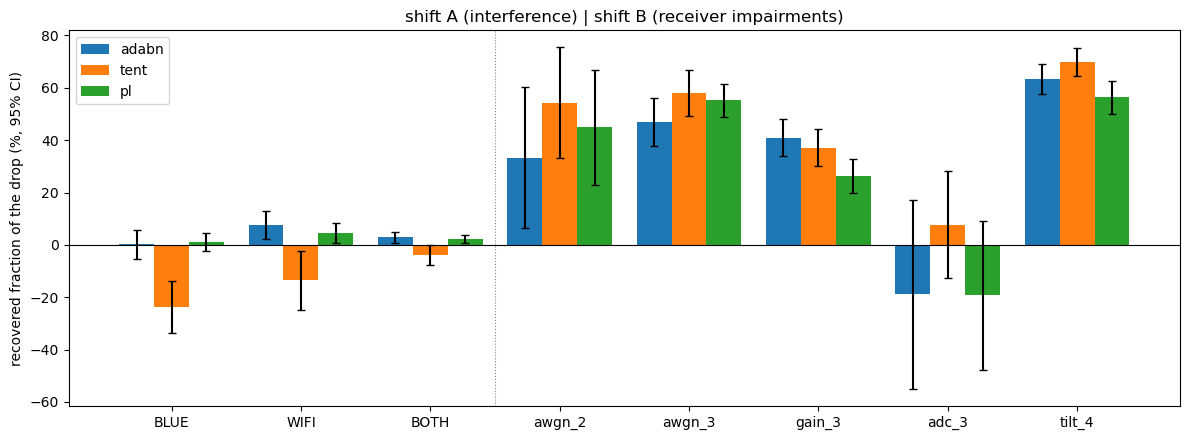

In [11]:
COLORS = dict(zip(METHODS[1:], plt.rcParams["axes.prop_cycle"].by_key()["color"]))
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(TARGETS))
for i, method in enumerate(METHODS[1:]):
    g = runs[runs.method == method].groupby("target", sort=False)["recovered"]
    mean, se = g.mean().reindex(TARGETS), (g.std() / np.sqrt(g.count())).reindex(TARGETS)
    ax.bar(x + (i - 1) * 0.27, 100 * mean, 0.27, yerr=196 * se, capsize=3, color=COLORS[method], label=method)
ax.axhline(0, color="black", lw=0.8); ax.axvline(2.5, color="grey", lw=0.8, ls=":")
ax.set_xticks(x, TARGETS); ax.set_ylabel("recovered fraction of the drop (%, 95% CI)")
ax.set_title("shift A (interference) | shift B (receiver impairments)"); ax.legend()
plt.tight_layout(); fig.savefig(os.path.join(out, "e3_recovery.png"), dpi=120, bbox_inches="tight"); plt.show()

In [12]:
# supplementary realistic-AGC target (agc_3): separate table, the 8-target E3 table above is unchanged
supp = build_rows(SUPP)
st = []
for (target, method), g in supp.groupby(["target", "method"], sort=False):
    src = supp[(supp.target == target) & (supp.method == "source")].set_index(["seed", "fold"])["macro_f1"]
    t = paired_test(g.set_index(["seed", "fold"])["macro_f1"].reindex(src.index), src)
    st.append({"target": target, "method": method, "gain": t["diff"], "ci_low": t["ci_lo"], "ci_high": t["ci_hi"],
               "wilcoxon_p": t["p"], "recovered_mean": g["recovered"].mean()})
e3_agc = pm(supp, ["accuracy", "macro_f1"], ["target", "method"]).join(pd.DataFrame(st).set_index(["target", "method"]))
e3_agc.to_csv(os.path.join(out, "e3_agc.csv"))
e3_agc.round(4)

accuracy         macro_f1    gain  ci_low  ci_high  \
target method                                                              
agc_3  source  0.8014 ± 0.0476  0.7850 ± 0.0647  0.0000  0.0000   0.0000   
       adabn   0.8066 ± 0.0455  0.7864 ± 0.0640  0.0014 -0.0194   0.0215   
       tent    0.8022 ± 0.0504  0.7829 ± 0.0664 -0.0021 -0.0267   0.0209   
       pl      0.8108 ± 0.0434  0.7891 ± 0.0647  0.0041 -0.0144   0.0216   

               wilcoxon_p  recovered_mean  
target method                              
agc_3  source         NaN          0.0000  
       adabn       0.5602          0.3198  
       tent        0.5782          0.4799  
       pl          0.3123          0.4371